# Task 1 Setting the baseline

## Imports

In [23]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import train_test_split, cross_val_predict, cross_val_score
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
import missingno as msno
import seaborn as sns

## Auxiliary functions

In [24]:
def cMSE(y, y_hat, c):
    err = y-y_hat
    err = (1-c)*err**2 + c*np.maximum(0,err)**2
    return np.sum(err)/err.shape[0]
    
def plot_y_yhat(y_test, y_pred, plot_title="plot"):
    # Only one target variable: SurvivalTime
    label = 'SurvivalTime'
    MAX = 500

    # Select indices for plotting
    if len(y_test) > MAX:
        idx = np.random.choice(len(y_test), MAX, replace=False)
    else:
        idx = np.arange(len(y_test))

    # Plot True vs Predicted for SurvivalTime
    plt.figure(figsize=(6, 6))
    x0 = np.min(y_test[idx])
    x1 = np.max(y_test[idx])
    plt.scatter(y_test[idx], y_pred[idx], alpha=0.7)
    plt.xlabel(f'True {label}')
    plt.ylabel(f'Predicted {label}')
    plt.plot([x0, x1], [x0, x1], color='red')
    plt.title(f'True vs Predicted {label}')
    plt.axis('square')
    plt.savefig(plot_title + '.pdf')
    plt.show()
    
def save_predictions(predictions, path):
    # Create a DataFrame with the 'id' column and the predictions
    df = pd.DataFrame({
        'id': range(len(predictions)),
        '0': predictions
    })
    
    # Save the DataFrame to a CSV file
    df.to_csv(path, index=False)

## Task 1.1 Data preparation and validation pipeline

### Load dataset

In [39]:
df = pd.read_csv('./mlNOVA/train_data.csv')
df.drop(columns=['id'], inplace=True)
df.head()

,Age,Gender,Stage,GeneticRisk,TreatmentType,ComorbidityIndex,TreatmentResponse,SurvivalTime,Censored
0,65.0,0,2,1.0,0,0.0,0.0,4.2,0
1,68.0,1,2,0.0,1,1.0,1.0,4.7,1
2,68.0,1,3,1.0,1,0.0,1.0,3.5,1
3,81.0,1,4,1.0,1,3.0,0.0,2.3,0
4,59.0,1,2,1.0,0,NaN,0.0,NaN,0


### Visualizations of missing data and correlation

In [ ]:
msno.bar(df)

In [ ]:
msno.heatmap(df)

In [ ]:
msno.matrix(df)

In [ ]:
msno.dendrogram(df)

### Drop the columns containing the features with missing data and the censored data points, or missing survival time.

In [40]:
# these columns have missing data ocasionally
df.drop(columns=['GeneticRisk', 'ComorbidityIndex', 'TreatmentResponse'], inplace=True)
# drop rows with missing Survival Time
df = df.dropna(subset=['SurvivalTime'])
# remove rows where 'Censored' is 1
df = df[df['Censored'] != 1]
print(f"Remaining points after removing censored rows: {df.shape[0]}")
# Display the first few rows of the cleaned dataset
df.head()

Remaining points after removing censored rows: 161


,Age,Gender,Stage,TreatmentType,SurvivalTime,Censored
0,65.0,0,2,0,4.2,0
3,81.0,1,4,1,2.3,0
5,47.0,1,4,1,2.6,0
9,68.0,1,1,0,6.4,0
11,56.0,0,2,0,4.1,0


### Check the pairplot between the remaining features and the target variable. Analyze and comment in the slides.

In [ ]:
sns.pairplot(df, kind="hist")

### Define the matrix X with the features as columns and examples as rows, and y as a vector with the Survival Time.

In [41]:
X = df.drop(columns=['SurvivalTime', 'Censored'])
y = df['SurvivalTime']
c = df['Censored']

# Display the shapes of X and y to verify
print(f"Feature matrix X shape: {X.shape}")
print(f"Target vector y shape: {y.shape}")
print(f"Censored vector c shape: {c.shape}")

X = np.array(X)
y = np.array(y)
c = np.array(c)

Feature matrix X shape: (161, 4)
Target vector y shape: (161,)
Censored vector c shape: (161,)


### Consider a train, validation and test split, against a train, test split, with cross validation. What validation procedure is more data-efficient? Justify your answer with evidence from the dataset.

## Task 1.2 Learn the baseline model

In [ ]:
# example with cross_val_score
# # Split the data: train (80%), test (20%)
# X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# print(f"Training set size: {X_train.shape[0]}")
# print(f"Test set size: {X_test.shape[0]}")

# # Cross-validation example (5-fold)
# model = LinearRegression()
# cv_scores = cross_val_score(model, X_train, y_train, cv=5, scoring='neg_mean_squared_error')
# print(f"Cross-validation MSE scores: {-cv_scores}")
# print(f"Average CV MSE: {-np.mean(cv_scores)}")

Data split; Cross-validation; Linear regression

In [42]:
# Train-test split
X_train, X_test, y_train, y_test, c_train, c_test = train_test_split(X, y, c, test_size=0.2, random_state=42)

In [43]:
# Define pipeline: StandardScaler + LinearRegression
linear_reg = make_pipeline(StandardScaler(),
                            LinearRegression())

# Perform cross-validation on the training set
y_pred_cv = cross_val_predict(linear_reg, X_train, y_train, cv=10)

# Calculate cMSE for cross-validation
cMSE_cv = cMSE(y_train, y_pred_cv, c_train)
print(f"Cross-Validation Censored Mean Squared Error (cMSE): {cMSE_cv}")

# Train the pipeline on the full training set
linear_reg.fit(X_train, y_train)

# Predict on the test set
y_pred_test = linear_reg.predict(X_test)

# Calculate cMSE for the test set
cMSE_test = cMSE(y_test, y_pred_test, c_test)
print(f"Test Set Censored Mean Squared Error (cMSE): {cMSE_test}")

Cross-Validation Censored Mean Squared Error (cMSE): 4.390046220294185
Test Set Censored Mean Squared Error (cMSE): 4.411178530294957


Linear regression y-y_hat plot

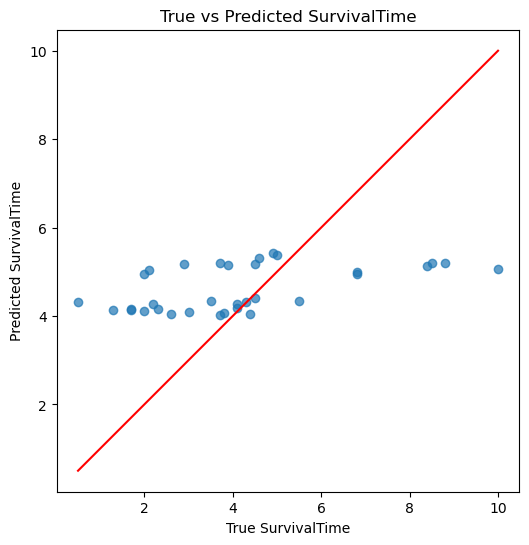

In [10]:
plot_y_yhat(y_test, y_pred_test, plot_title="y_yhat_plot")

Load Kaggle dataset and process it as needed

In [11]:
X_kaggle_df = pd.read_csv('./mlNOVA/test_data.csv')
X_kaggle_df.drop(columns=['id'], inplace=True)
# these columns have missing data ocasionally
X_kaggle_df.drop(columns=['GeneticRisk', 'ComorbidityIndex', 'TreatmentResponse'], inplace=True)
# drop rows with missing Survival Time or any other missing value
X_kaggle_df = X_kaggle_df.dropna()
# Display the first few rows of the cleaned dataset
X_kaggle_df.head()

,Age,Gender,Stage,TreatmentType
0,71.0,1,4,1
1,57.0,1,4,0
2,66.0,0,2,0
3,73.0,0,3,1
4,53.0,1,4,0


Save prediction

In [12]:
y_baseline_pred = linear_reg.predict(X_kaggle_df)
save_predictions(y_baseline_pred, './submissions/baseline-submission-01.csv')

c:\Users\rasvi\anaconda3\envs\ml\Lib\site-packages\sklearn\base.py:486: UserWarning: X has feature names, but StandardScaler was fitted without feature names
  warnings.warn(


## Task 1.3 Learn with the cMSE

### Compute the expression of the derivative of the cMSE loss, where it is defined.

$$
\frac{\partial cMSE}{\partial \hat{y}_n} =
\begin{cases} 
-\frac{2}{N}(y_n - \hat{y}_n), & \text{if } c_n = 0, \\
-\frac{2}{N}(y_n - \hat{y}_n), & \text{if } c_n = 1 \text{ and } y_n - \hat{y}_n > 0, \\
0, & \text{if } c_n = 1 \text{ and } y_n - \hat{y}_n \leq 0.
\end{cases}
$$


Simplified final expression

$$
\frac{\partial cMSE}{\partial \hat{y}_n} =
-\frac{2}{N} \left[ (1 - c_n)(y_n - \hat{y}_n) + c_n \max(0, y_n - \hat{y}_n) \right]
$$


### Implement Gradient Descent as a Python function, using the derivative above.

Gradient descent with linear regression

In [30]:
def gradient_descent(X, y, c, learning_rate=0.01, iterations=1000, threshold=1e-6, regularization=None, alpha=0.01):
    N, M = X.shape
    weights = np.zeros(M)  # Initialize weights to zeros
    bias = 0.0  # Initialize intercept
    losses = []  # To track the loss at each epoch
    previous_loss = None

    for iteration in range(iterations):
        # Linear regression prediction
        y_hat = X @ weights + bias

        # Calculate the gradientS
        sub_expression = (1 - c) * (y - y_hat) + c * np.maximum(0, y - y_hat)
        gradient = (X.T @ (-2 * sub_expression)) / N  # Gradient for weights
        bias_gradient = np.mean(-2 * sub_expression)  # Gradient for bias

        # Add regularization to the gradient for weights
        if regularization == 'ridge':
            gradient += 2 * alpha * weights  # L2 regularization term
        elif regularization == 'lasso':
            gradient += alpha * np.sign(weights)  # L1 regularization term

        # Update weights and bias
        weights -= learning_rate * gradient
        bias -= learning_rate * bias_gradient

        # Calculate regularized loss
        regularization_term = 0
        if regularization == 'ridge':
            regularization_term = alpha * np.sum(weights**2)
        elif regularization == 'lasso':
            regularization_term = alpha * np.sum(np.abs(weights))
        
        current_loss = cMSE(y, y_hat, c) + regularization_term
        
        if previous_loss and abs(previous_loss - current_loss) <= threshold:
            break
        
        previous_loss = current_loss
        losses.append(current_loss)

        # print loss for debugging
        if iteration % 100 == 0:
            print(f"Iteration {iteration}: cMSE = {current_loss}")

    return weights, bias, losses

### Run Gradient Descent on your problem, and evaluate the model.

Transform X and y into numpy arrays; Split them into training and test set; Scale them with standard scaler

##### Pre-processing

In [31]:
df = pd.read_csv('./mlNOVA/train_data.csv')
df.drop(columns=['id'], inplace=True)
df.head()

,Age,Gender,Stage,GeneticRisk,TreatmentType,ComorbidityIndex,TreatmentResponse,SurvivalTime,Censored
0,65.0,0,2,1.0,0,0.0,0.0,4.2,0
1,68.0,1,2,0.0,1,1.0,1.0,4.7,1
2,68.0,1,3,1.0,1,0.0,1.0,3.5,1
3,81.0,1,4,1.0,1,3.0,0.0,2.3,0
4,59.0,1,2,1.0,0,NaN,0.0,NaN,0


In [32]:
# these columns have missing data ocasionally
df.drop(columns=['GeneticRisk', 'ComorbidityIndex', 'TreatmentResponse'], inplace=True)
# drop rows with missing Survival Time
df = df.dropna(subset=['SurvivalTime'])

print(f"Remaining points after cleaning rows: {df.shape[0]}")
# Display the first few rows of the cleaned dataset
df.head()

Remaining points after cleaning rows: 240


,Age,Gender,Stage,TreatmentType,SurvivalTime,Censored
0,65.0,0,2,0,4.2,0
1,68.0,1,2,1,4.7,1
2,68.0,1,3,1,3.5,1
3,81.0,1,4,1,2.3,0
5,47.0,1,4,1,2.6,0


In [33]:
X = df.drop(columns=['SurvivalTime', 'Censored'])
y = df['SurvivalTime']
c = df['Censored']

# Display the shapes of X and y to verify
print(f"Feature matrix X shape: {X.shape}")
print(f"Target vector y shape: {y.shape}")
print(f"Censored vector c shape: {c.shape}")

X = np.array(X)
y = np.array(y)
c = np.array(c)

Feature matrix X shape: (240, 4)
Target vector y shape: (240,)
Censored vector c shape: (240,)


In [36]:
# Train-test split
X_train, X_test, y_train, y_test, c_train, c_test = train_test_split(X, y, c, test_size=0.2, random_state=42)

# Standardize the features
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

### Experiment with Lasso and Ridge regularization.

#### With gradient descent

No regularization

Iteration 0: cMSE = 24.105260416666667
Iteration 100: cMSE = 3.6849159741777293
Iteration 200: cMSE = 3.102564151058042
Iteration 300: cMSE = 3.074609314194659
Iteration 400: cMSE = 3.073082945573747
Test Set Censored Mean Squared Error (cMSE): 3.6971109194119975


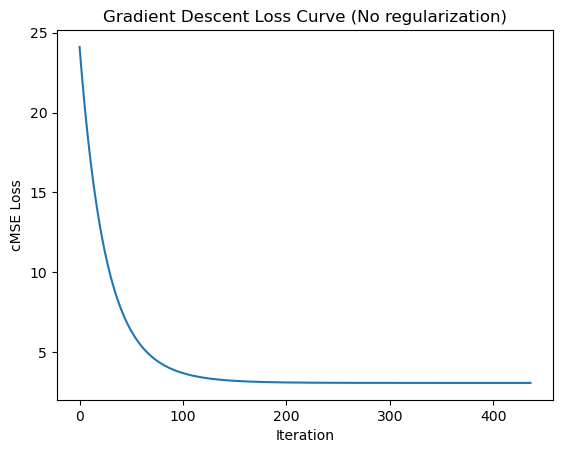

array([ 0.10888996, -0.02325983,  0.02521334,  0.61941154])

In [37]:
weights, bias, losses = gradient_descent(
    X_train_scaled, y_train, c_train, learning_rate=0.01, iterations=1000, regularization=None
)

# Make predictions on the test set
y_pred_test = X_test_scaled @ weights + bias

# Evaluate the model on the test set
cMSE_test = cMSE(y_test, y_pred_test, c_test)
print(f"Test Set Censored Mean Squared Error (cMSE): {cMSE_test}")

# Plot the loss curve
plt.plot(losses)
plt.xlabel("Iteration")
plt.ylabel("cMSE Loss")
plt.title("Gradient Descent Loss Curve (No regularization)")
plt.show()

weights

Ridge

Iteration 0: cMSE = 24.10526153423744
Iteration 100: cMSE = 3.687681878508591
Iteration 200: cMSE = 3.1063102598708774
Iteration 300: cMSE = 3.0785384116726475
Iteration 400: cMSE = 3.0770366041634847
Test Set Censored Mean Squared Error (cMSE): 3.698608210939225


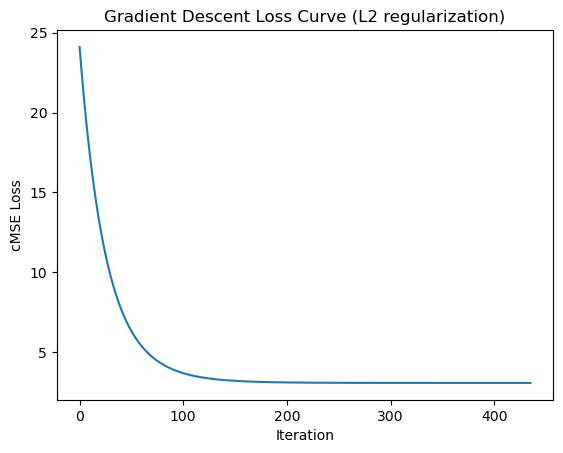

array([ 0.10764752, -0.02370077,  0.02572187,  0.61147935])

In [18]:
weights_ridge, bias_ridge, losses_ridge = gradient_descent(
    X_train_scaled, y_train, c_train, learning_rate=0.01, iterations=1000, regularization='ridge', alpha=0.01
)

# Make predictions on the test set
y_pred_test = X_test_scaled @ weights_ridge + bias_ridge

# Evaluate the model on the test set
cMSE_test = cMSE(y_test, y_pred_test, c_test)
print(f"Test Set Censored Mean Squared Error (cMSE): {cMSE_test}")

# Plot the loss curve
plt.plot(losses_ridge)
plt.xlabel("Iteration")
plt.ylabel("cMSE Loss")
plt.title("Gradient Descent Loss Curve (L2 regularization)")
plt.show()

weights_ridge

Lasso

Iteration 0: cMSE = 24.105391136820046
Iteration 100: cMSE = 3.6915734550618082
Iteration 200: cMSE = 3.1102047037497003
Iteration 300: cMSE = 3.0823062373817587
Iteration 400: cMSE = 3.0807793441857494
Test Set Censored Mean Squared Error (cMSE): 3.6973783770786555


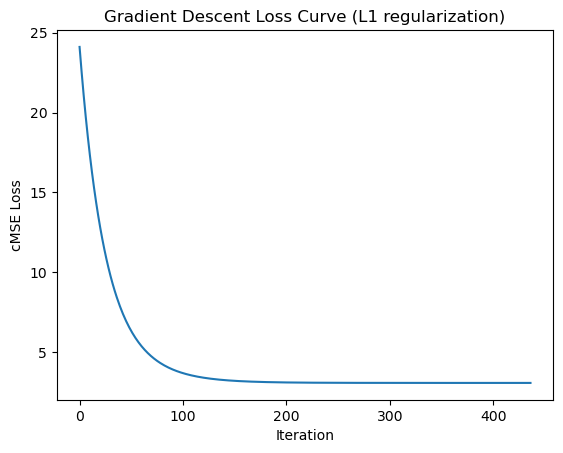

array([ 0.10444899, -0.01820204,  0.02132665,  0.61378737])

In [19]:
weights_lasso, bias_lasso, losses_lasso = gradient_descent(
    X_train_scaled, y_train, c_train, learning_rate=0.01, iterations=1000, regularization='lasso', alpha=0.01
)

# Make predictions on the test set
y_pred_test = X_test_scaled @ weights_lasso + bias_lasso

# Evaluate the model on the test set
cMSE_test = cMSE(y_test, y_pred_test, c_test)
print(f"Test Set Censored Mean Squared Error (cMSE): {cMSE_test}")

# Plot the loss curve
plt.plot(losses_lasso)
plt.xlabel("Iteration")
plt.ylabel("cMSE Loss")
plt.title("Gradient Descent Loss Curve (L1 regularization)")
plt.show()

weights_lasso

### Submit the predictions of the learned model to Kaggle

Load kaggle dataset

In [21]:
X_kaggle_df = pd.read_csv('./mlNOVA/test_data.csv')
X_kaggle_df.drop(columns=['id'], inplace=True)
# these columns have missing data ocasionally
X_kaggle_df.drop(columns=['GeneticRisk', 'ComorbidityIndex', 'TreatmentResponse'], inplace=True)
# drop rows with missing Survival Time or any other missing value
X_kaggle_df = X_kaggle_df.dropna()
X_kaggle_df = np.array(X_kaggle_df)
# Standardize the features
X_kaggle_df_scaled = scaler.transform(X_kaggle_df)

Save prediction from gradient descent with linear regression

In [22]:
y_gradient_pred = X_kaggle_df_scaled @ weights + bias
save_predictions(y_gradient_pred, './submissions/cMSE-baseline-submission-02.csv')